# 1. Useless Connections

> **Overview.** Growth only adds connections, so an LTU keeps every wrong input it reads. Do wrong inputs still cost
> anything once the LTU has learned, and can it tell them apart from right ones?

**Setup.** The target and LTUs of `../step_by_step/3_connect_to_everything.ipynb`, added at step 0 with initial
step-size $3 \times 10^{-2}$. Each LTU reads its target LTU's 10 inputs and $n$ other inputs drawn at random. No growth
or search. 5 seeds; 500k steps.
- **1a.** $n$ = 0, 10 or 100.
- **1b.** At $n$ = 100, the LTUs' weights on their right and on their wrong inputs: their size, and how often they
  change sign.
- **1c.** At $n$ = 100, with and without *pruning*: every 10k steps, each LTU stops reading the inputs whose weight has
  changed sign since the last pruning.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of the LTUs' input weights

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between prunings, and between sign checks

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # Each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at random, with
    # random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

The learner of `../step_by_step/3_connect_to_everything.ipynb`, and `prune`.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere


def init_net(key, target, extra):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs, `extra` other inputs drawn at random, and
    # the bias, with LeCun uniform weights over their fan-in; their shadow weights +1 and -1, on a random output that
    # reads that target LTU. Every other weight 0.
    w_key, extra_key, out_key = jax.random.split(key, 3)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    right = target.w[assigned] != 0
    others = jnp.argsort(jnp.argsort(jnp.where(right, jnp.inf, jax.random.uniform(extra_key, right.shape)))) < extra
    reads = jnp.append(right | others, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES + extra
    readers = target.out[:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow)


def add(net, step_size):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at step_size.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(step_size), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and the squared error on this sample averaged over the outputs, before learning from it.
    # `probe` is zero; its gradient is the error arriving at each LTU.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean)

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(N_LTUS))
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss / N_OUTPUTS


def prune(net, signs):
    # Each LTU stops reading every input whose weight's sign differs from `signs`, its sign at the last pruning (0 for
    # none yet); the bias stays.
    w = net.w['hidden'][:, :-1]
    reads = net.reads.at[:, :-1].set(net.reads[:, :-1] & ((signs == 0) | (jnp.sign(w) == signs)))
    return net._replace(reads=reads, w={**net.w, 'hidden': net.w['hidden'] * reads})

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, prunes):
    # NUM_STEPS online network-Autostep steps on samples from `target`, the LTUs added at step 0. Every PERIOD steps,
    # the weights' signs are checked against those at the last check, and the LTUs pruned if prunes. Returns each
    # window's mean squared error; the LTUs' mean |weight| on their right inputs and on the wrong inputs they read, at
    # the window's end; and, at each check, the share of right and of wrong inputs whose weight changed sign since the
    # last check (nan between checks).
    right = target.w[jnp.arange(N_LTUS) // 2 % N_TARGETS] != 0

    def window(carry, inputs):
        net, signs = carry
        index, key = inputs
        net, mse = jax.lax.scan(lambda net, k: learn(net, *sample(target, k)), net, jax.random.split(key, WINDOW))
        due = (index + 1) * WINDOW % PERIOD == 0
        w, wrong = net.w['hidden'][:, :-1], net.reads[:, :-1] & ~right
        changed = (signs != 0) & (jnp.sign(w) != signs)
        share = lambda m: jnp.where(due & (index >= PERIOD // WINDOW), (changed & m).sum() / jnp.maximum(m.sum(), 1),
                                    jnp.nan)
        stats = (mse.mean(), (jnp.abs(w) * right).sum() / right.sum(),
                 (jnp.abs(w) * wrong).sum() / jnp.maximum(wrong.sum(), 1), share(right), share(wrong))
        net = pick(prunes & due, prune(net, signs), net)
        signs = jnp.where(due, jnp.sign(net.w['hidden'][:, :-1]) * net.reads[:, :-1], signs)
        return (net, signs), stats

    n = NUM_STEPS // WINDOW
    start = (add(net, FAST_STEP_SIZE), jnp.zeros_like(net.w['hidden'][:, :-1]))
    return jax.lax.scan(window, start, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (extra, prunes) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same target network
    # and samples. Returns {config: the RMSE of each window, shaped (seed, window)} and {config: the mean |weight| on
    # right and on wrong inputs, then the share of each that changed sign, each shaped (seed, window)}.
    extra, prunes, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(init_net)(keys(0), targets, extra)
    mse, *weights = (np.asarray(a).reshape(len(configs), N_SEEDS, -1)
                     for a in jax.jit(jax.vmap(train))(nets, keys(1), targets, prunes))
    return dict(zip(configs, np.sqrt(mse))), dict(zip(configs, zip(*weights)))

## Runs

In [6]:
EXTRA = (0, 10, 100)
KEPT = {n: (n, False) for n in EXTRA}
PRUNED = (100, True)
started = perf_counter()
rmse, weights = run([*KEPT.values(), PRUNED])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

20 runs in 123s


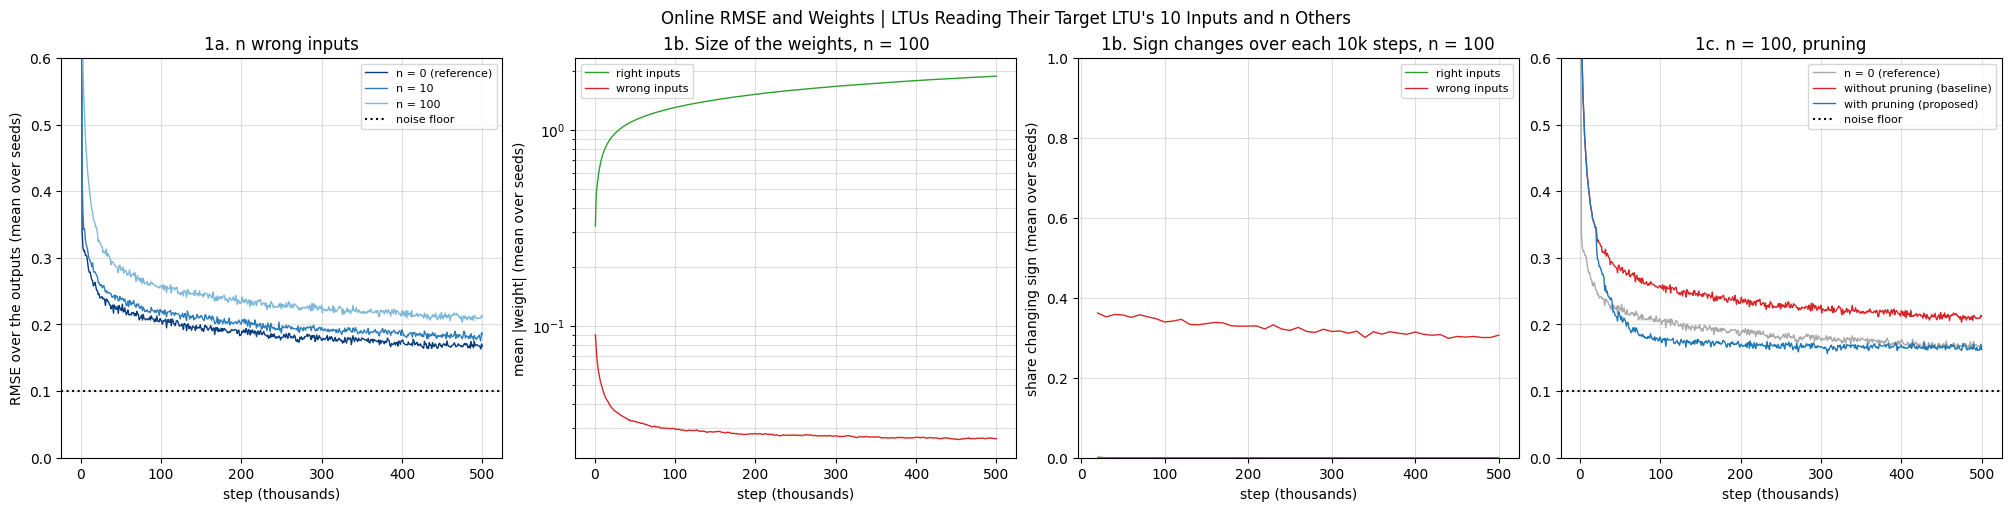

In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW


def finish(ax, title):
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step (thousands)', ylim=(0, 0.6), title=title)
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(1, 4, figsize=(20, 5), layout='constrained')
for i, n in enumerate(EXTRA):
    axes[0].plot(STEPS / 1000, rmse[KEPT[n]].mean(0), color=plt.cm.Blues(0.95 - 0.25 * i), lw=1,
                 label=f'n = {n}' + (' (reference)' if n == 0 else ''))
finish(axes[0], '1a. n wrong inputs')
axes[0].set_ylabel('RMSE over the outputs (mean over seeds)')

right, wrong, right_changed, wrong_changed = weights[KEPT[100]]
checks = ~np.isnan(right_changed[0])
for ax, (r, w), ylabel, title in (
        (axes[1], (right, wrong), 'mean |weight| (mean over seeds)', '1b. Size of the weights, n = 100'),
        (axes[2], (right_changed, wrong_changed), 'share changing sign (mean over seeds)',
         '1b. Sign changes over each 10k steps, n = 100')):
    at = checks if ax is axes[2] else slice(None)
    ax.plot(STEPS[at] / 1000, r[:, at].mean(0), color='tab:green', lw=1, label='right inputs')
    ax.plot(STEPS[at] / 1000, w[:, at].mean(0), color='tab:red', lw=1, label='wrong inputs')
    ax.set(xlabel='step (thousands)', ylabel=ylabel, title=title)
    ax.grid(alpha=0.4, which='both')
    ax.legend(fontsize=8)
axes[1].set_yscale('log')
axes[2].set_ylim(0, 1)

axes[3].plot(STEPS / 1000, rmse[KEPT[0]].mean(0), color='darkgray', lw=1, label='n = 0 (reference)')
axes[3].plot(STEPS / 1000, rmse[KEPT[100]].mean(0), color='tab:red', lw=1, label='without pruning (baseline)')
axes[3].plot(STEPS / 1000, rmse[PRUNED].mean(0), color='tab:blue', lw=1, label='with pruning (proposed)')
finish(axes[3], '1c. n = 100, pruning')
fig.suptitle(f"Online RMSE and Weights | LTUs Reading Their Target LTU's {N_SOURCES} Inputs and n Others")
plt.show()

## Results

- **1a.** Wrong inputs cost accuracy for as long as an LTU reads them, more the more there are.
- **1b.** An LTU tells them apart: its weights on wrong inputs shrink but jitter around zero, often changing sign, while
  those on right inputs keep their sign.
- **1c.** So pruning the inputs whose weight changed sign removes the wrong ones and recovers the accuracy of reading
  right inputs alone.

## Details

**Target and learner.** As in `../step_by_step/3_connect_to_everything.ipynb`: 8 target LTUs, each reading 10 of
1000 standard normal inputs with weights $\pm 1$, and 10 outputs, each reading 4 target LTUs. Two LTUs per target LTU,
each with its shadow weight on an output that reads that target LTU. Here the LTUs are added at step 0, with no
linear-learner phase.

**Why wrong weights stay.** An LTU's output is a step, so a small weight on a wrong input rarely changes it, and the
loss barely pulls the weight back to zero. Meanwhile the backward pass (the sigmoid's derivative) keeps nudging it, and
Autostep keeps its step-size about as large as the right inputs'. So wrong weights jitter around zero. Together they
add noise to the LTU's input, which flips the LTU near its threshold.

**Pruning.** Every 10k steps, each LTU stops reading every input whose weight's sign differs from its sign at the
last pruning (never the bias). An input is first checked at the second pruning after it is read, so a weight may
change sign once while it learns. The rule has no threshold: only the period, which search already has.

**Why not cut small weights.** A target LTU's weights can be small too: with $N(0, 1)$ target weights (as in the deep
target network), the LTUs learn weights just as spread out, and cutting those below a tenth of an LTU's largest cuts
16% of the right inputs and ends worse than not pruning (checked separately, 5 seeds). The sign rule keeps 96% of
them there, and loses only the weakest, whose weights are within the jitter.

**Why pruned LTUs start faster than $n$ = 0.** Reading 110 inputs at first, Autostep's normalization cuts their
step-sizes about 3-fold, and the smaller steps remain after pruning: less noise early on.